# Prepare a simulation bank

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


METIS needs simulator inputs paired with their output trajectories. You can
supply arrays, a data frame or a Parquet file. This walkthrough creates a small
SIRDS bank and saves it for reuse.

## One row per time point

Use one column for each input and output, a time column (`t`) and a replicate
identifier (`rep`). Inputs stay constant within a realisation. Replicate IDs
separate stochastic realisations at the same inputs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from metis import SimulationDataset
from metis.datasets.sirds import simulate_sirds

parameters = dict(I0=0.005, beta=0.4, gamma=0.1, omega=0.02, mu=0.01)
S, I, R, D = simulate_sirds(**parameters, T=40, seed=0)
frame = pd.DataFrame({
    "rep": 0, "t": np.arange(1, 41),
    "S": S[1:], "I": I[1:], "R": R[1:], "D": D[1:],
    **parameters,
})
frame.head()

,rep,t,S,I,R,D,I0,beta,gamma,omega,mu
0,0,1,993,7,0,0,0.005,0.4,0.1,0.02,0.01
1,0,2,993,6,1,0,0.005,0.4,0.1,0.02,0.01
2,0,3,990,8,2,0,0.005,0.4,0.1,0.02,0.01
3,0,4,985,13,2,0,0.005,0.4,0.1,0.02,0.01
4,0,5,979,19,2,0,0.005,0.4,0.1,0.02,0.01


Here we omit day zero, the known initial state. We use exactly the same daily
grid in every realisation; METIS does not interpolate missing times.

## Sample the input space

For a quick example, vary transmission and recovery rates at 30 settings and
simulate three replicates at each. Keep the other inputs fixed. The independent
uniform draws below are a demonstration design; choose ranges and a sampling
design appropriate to your model for a research bank.

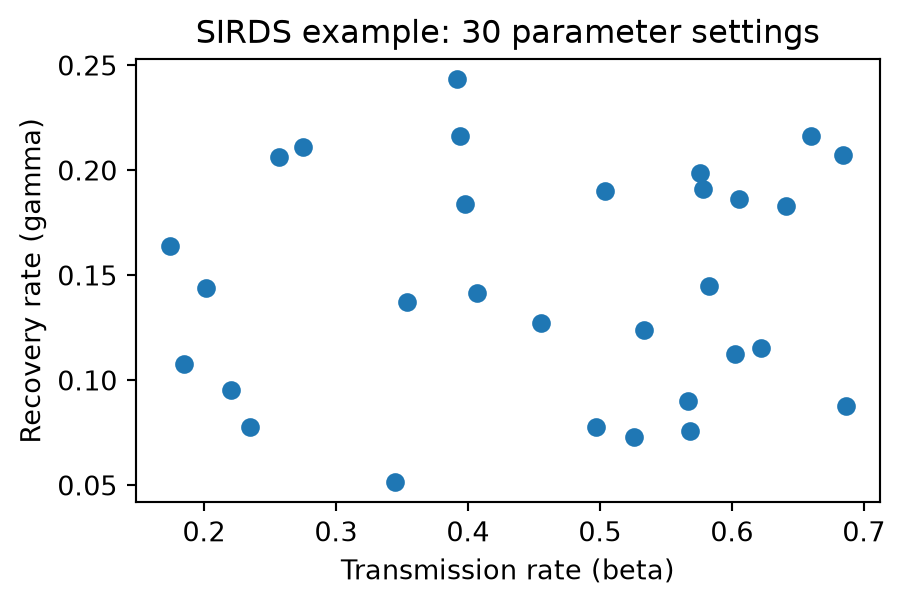

In [2]:
rng = np.random.default_rng(42)
settings = pd.DataFrame({
    "beta": rng.uniform(0.15, 0.7, 30),
    "gamma": rng.uniform(0.05, 0.25, 30),
})
fig, ax = plt.subplots(figsize=(5, 3))
ax.scatter(settings.beta, settings.gamma)
ax.set(xlabel="Transmission rate (beta)", ylabel="Recovery rate (gamma)",
       title="SIRDS example: 30 parameter settings")
plt.show()

## Simulate and combine

In [3]:
frames = []
for setting, row in settings.iterrows():
    inputs = dict(I0=0.02, beta=row.beta, gamma=row.gamma, omega=0.02, mu=0.01)
    for rep in range(3):
        S, I, R, D = simulate_sirds(**inputs, T=40, seed=3 * setting + rep)
        frames.append(pd.DataFrame({
            "rep": rep, "t": np.arange(1, 41),
            "S": S[1:], "I": I[1:], "R": R[1:], "D": D[1:],
            **inputs,
        }))
frame = pd.concat(frames, ignore_index=True)
print(f"{len(settings)} settings × 3 replicates × 40 days = {len(frame):,} rows")
frame.head()

30 settings × 3 replicates × 40 days = 3,600 rows


,rep,t,S,I,R,D,I0,beta,gamma,omega,mu
0,0,1,968,30,2,0,0.02,0.575676,0.198952,0.02,0.01
1,0,2,959,31,9,1,0.02,0.575676,0.198952,0.02,0.01
2,0,3,940,43,15,2,0.02,0.575676,0.198952,0.02,0.01
3,0,4,929,44,25,2,0.02,0.575676,0.198952,0.02,0.01
4,0,5,910,52,36,2,0.02,0.575676,0.198952,0.02,0.01


## Validate and split

Tell METIS which columns are inputs and outputs. It checks the grid, duplicate
rows, missing values and whether inputs stay constant within each realisation.
The split keeps all replicates at the same parameter setting together.

In [4]:
bank = SimulationDataset.from_frame(
    frame,
    inputs=["I0", "beta", "gamma", "omega", "mu"],
    outputs=["S", "I", "R", "D"],
)
split = bank.split(seed=42)
print("Input array:", bank.inputs.shape)
print("Output array:", bank.outputs.shape)
print("Realisations in train / validation / test:",
      len(split.train.inputs), len(split.validation.inputs), len(split.test.inputs))

Input array: (90, 5)
Output array: (90, 40, 4)
Realisations in train / validation / test: 54 18 18


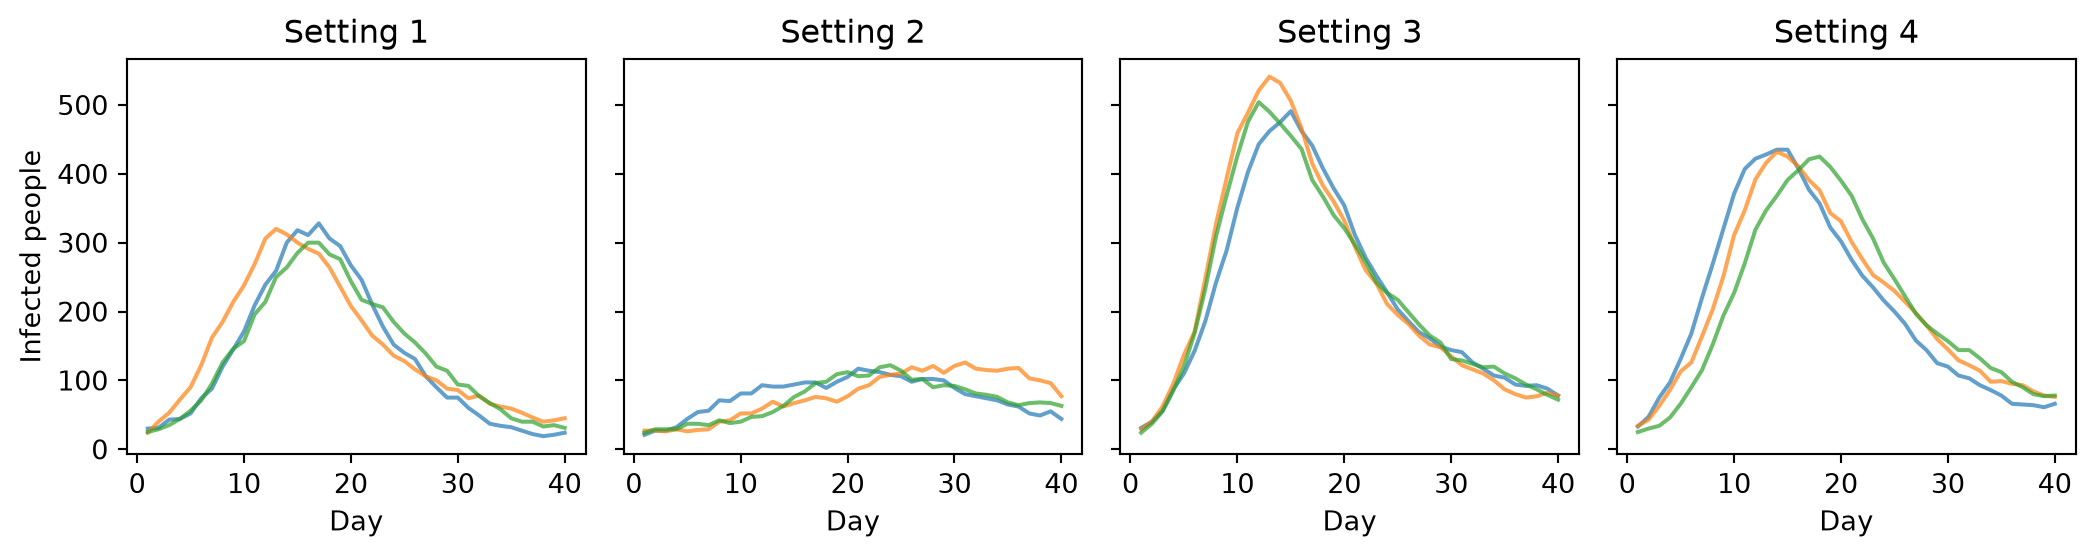

In [5]:
#| fig-cap: "SIRDS example bank: infected trajectories from the first four parameter settings, with three replicates per setting."
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharex=True, sharey=True)
for ax, setting in zip(axes, range(4)):
    start = setting * 3 * 40
    subset = frame.iloc[start:start + 3 * 40]
    for _, trajectory in subset.groupby("rep"):
        ax.plot(trajectory.t, trajectory.I, alpha=0.7)
    ax.set(title=f"Setting {setting + 1}", xlabel="Day")
axes[0].set_ylabel("Infected people")
fig.tight_layout()
plt.show()

*SIRDS example bank: infected trajectories from the first four parameter settings, with three replicates per setting.*

## Save for another session

In [6]:
frame.to_parquet("sirds_data.parquet", index=False)
print("Saved sirds_data.parquet")

Saved sirds_data.parquet


You can now [train a surrogate](https://ojwatson.github.io/metis/package/quickstart.html), replacing
`load_example()` with `SimulationDataset.from_parquet("sirds_data.parquet", ...)`
and the input/output names above. For CSV files from your own model, follow the
[own-bank walkthrough](https://ojwatson.github.io/metis/package/own-bank.html).